In [1]:
# === Google Colab 自動環境セットアップ ===
# ※ローカル環境では安全に無視され、Colab環境でのみ自動実行されます
import os, sys
repo_root = os.path.abspath(os.path.join(os.getcwd(), "..") if os.path.basename(os.getcwd()) == "3" else os.getcwd())
if repo_root not in sys.path:
    sys.path.insert(0, repo_root)

if 'google.colab' in str(get_ipython()):
    print("Google Colab 環境を検出しました。環境構築を開始します...")
    if not os.path.exists("study-mikanos"):
        !git clone https://github.com/miyayudai/study-mikanos.git
    %cd study-mikanos
    !pip install -q -r requirements.txt
    !pip install -q -e .
    !cmake -B build -S . > /dev/null && cmake --build build --target ch03_pointer_assembly_sim > /dev/null
    print("セットアップが完了しました。作業ディレクトリ:", os.getcwd())
else:
    print(f"ローカル実行環境です。(リポジトリルート: {repo_root})")


ローカル実行環境です。(リポジトリルート: /home/student/Documents/GitHub/study-mikanos)


# 3.7 ポインタ入門(2)：ポインタとアセンブリ言語 (`Pointers & Assembly Level`)
## 『ゼロからのOS自作入門』 第3章 画面表示の練習とブートローダ

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/miyayudai/study-mikanos/blob/main/3/3.7_Pointers_Part2_Assembly_Level.ipynb)

---

### 🎯 本節の学習目標
1. **ポインタの物理的実体**: C/C++ におけるポインタ操作が、x86-64 CPU とメモリバスの間で物理的にどのような機械語命令（`MOV`, `LEA`）に変換されるのかを完全に解き明かす。
2. **x86-64 データ転送命令とメモリアクセスサイズ**: Intel 記法におけるブラケット `[...]` の意味、および `BYTE PTR`, `WORD PTR`, `DWORD PTR`, `QWORD PTR` と C/C++ 型サイズの厳密な対応関係をマスターする。
3. **SIB (Scale-Index-Base) ハードウェアアドレッシングの数理導出**: 物理 CPU のアドレッシング計算式 `Base + Index × Scale + Disp` と、C言語の配列アクセス `p[i]` / ポインタ加算 `*(p + i)` のスケールファクタ（1, 2, 4, 8）との驚くべきハードウェア的一致を数理的に証明する。
4. **`LEA` (Load Effective Address) vs `MOV` 命令の決定的な違い**: メモリバスアクセスを一切伴わない純粋なアドレス計算・算術演算命令 `LEA` と、メモリ間接参照を行う `MOV` のハードウェア動作を対比する。
5. **ローカル変数とスタックポインタ (`RBP`, `RSP`)**: アドレス演算子 `&x` がどのようにスタック相対アドレッシングに展開されるかを理解し、ダングリングポインタ（Dangling Pointer）が発生する物理的メカニズムを暴く。
6. **フレームバッファ描画コードの逆アセンブル解析**: 第3章 3.5節で実装したピクセル描画ループが、コンパイラ最適化（`-O0` vs `-O2`）によってどのように SIMD（SSE/AVX: `movups`, `vmovdqu`）へ自動ベクトル化されるかを逆アセンブルで検証する。
7. **低レイヤにおける最適化の落とし穴と `volatile` の不可欠性**: コンパイラによる Dead Store Elimination（不要書き込みの除去）の原理を学び、なぜ VRAM や MMIO レジスタへのアクセスには `volatile` 修飾子が絶対に不可欠なのかを体得する。


## 1. なぜポインタとアセンブリ言語の対応理解が OS 開発で不可欠なのか？

### 高級言語の抽象化のベールを剥ぎ取る
一般的なアプリケーション開発では、ポインタは「メモリ上の変数を指し示す矢印」のような抽象的な概念として扱われます。
しかし、OS カーネルやブートローダを自作する**ベアメタル（Bare Metal: OSが存在しない生ハードウェア）環境**においては、そのような甘い抽象化は通用しません。

物理 CPU（x86-64）のシリコンダイ上には、「ポインタ」という型やオブジェクトは**一切存在しません**。
CPU に存在するのは以下の3つの物理要素だけです：
1. **汎用レジスタ (General Purpose Registers)**: 64ビットの高速なオンチップ記憶素子（`RAX`, `RBX`, `RCX`, `RDX`, `RSI`, `RDI`, `RBP`, `RSP`, `R8`〜`R15`）
2. **内部 ALU (Arithmetic Logic Unit: 演算装置)**: 加算・乗算・ビットシフトを行う演算回路
3. **メモリバス / キャッシュ階層 (Memory Bus & Cache Hierarchy)**: アドレスバスに番地（Address）を出力し、データバスを介して主記憶（DRAM）や MMIO デバイスとバイト列をやり取りするインターフェース

```mermaid
flowchart LR
    subgraph CPU["x86-64 CPU Core"]
        direction TB
        REG["汎用レジスタ群\n(RAX, RDI, RSI...)"]
        ALU["ALU / AGU (Address Gen)\nBase + Index * Scale + Disp"]
        L1["L1/L2 データキャッシュ"]
    end
    
    subgraph BUS["システムバス / インターコネクト"]
        ADDR_BUS["アドレスバス (64-bit Address)"]
        DATA_BUS["データバス (8/16/32/64/128-bit Data)"]
    end
    
    subgraph TARGET["物理アドレス空間 (Physical Memory)"]
        RAM["メインメモリ (DRAM)\nカーネルスタック・データ"]
        VRAM["GOP フレームバッファ (VRAM)\n画面のピクセル配列"]
        MMIO["PCI / xHCI レジスタ (MMIO)\nハードウェア制御ポート"]
    end

    REG -->|ベース・インデックス| ALU
    ALU -->|有効アドレス| L1
    L1 -->|キャッシュミス / ストア| ADDR_BUS
    REG <-->|読み書きデータ| DATA_BUS
    ADDR_BUS --> RAM
    ADDR_BUS --> VRAM
    ADDR_BUS --> MMIO
    DATA_BUS <--> RAM
    DATA_BUS <--> VRAM
    DATA_BUS <--> MMIO
```

### ポインタの正体とは「アドレスバスに出力される数値」である
C++ で `uint8_t* p = ...;` と書いたとき、変数 `p` に格納されている実体は、単なる **64ビットの符号なし整数（メモリアドレス）** に過ぎません。
そして間接参照 `*p = 255;` を実行した瞬間、CPU はレジスタ `p` の値をアドレスバスに送り出し、データバスに `0xFF` を流してメモリや VRAM のフリップフロップを励起させます。

もしプログラマがポインタのアセンブリ言語変換を理解していなければ：
- ポインタのインクリメント `p++` で何バイトアドレスが進むのか？
- 4バイト整数 `uint32_t*` を 4バイト境界に揃えない（アンアライメントアクセス）と何が起きるのか？
- なぜループ内のピクセル書き込みがコンパイラによって勝手に消去されてしまうのか？
といった低レイヤ特有の致命的なバグに直面した際、原因を突き止めることが原理的に不可能になります。


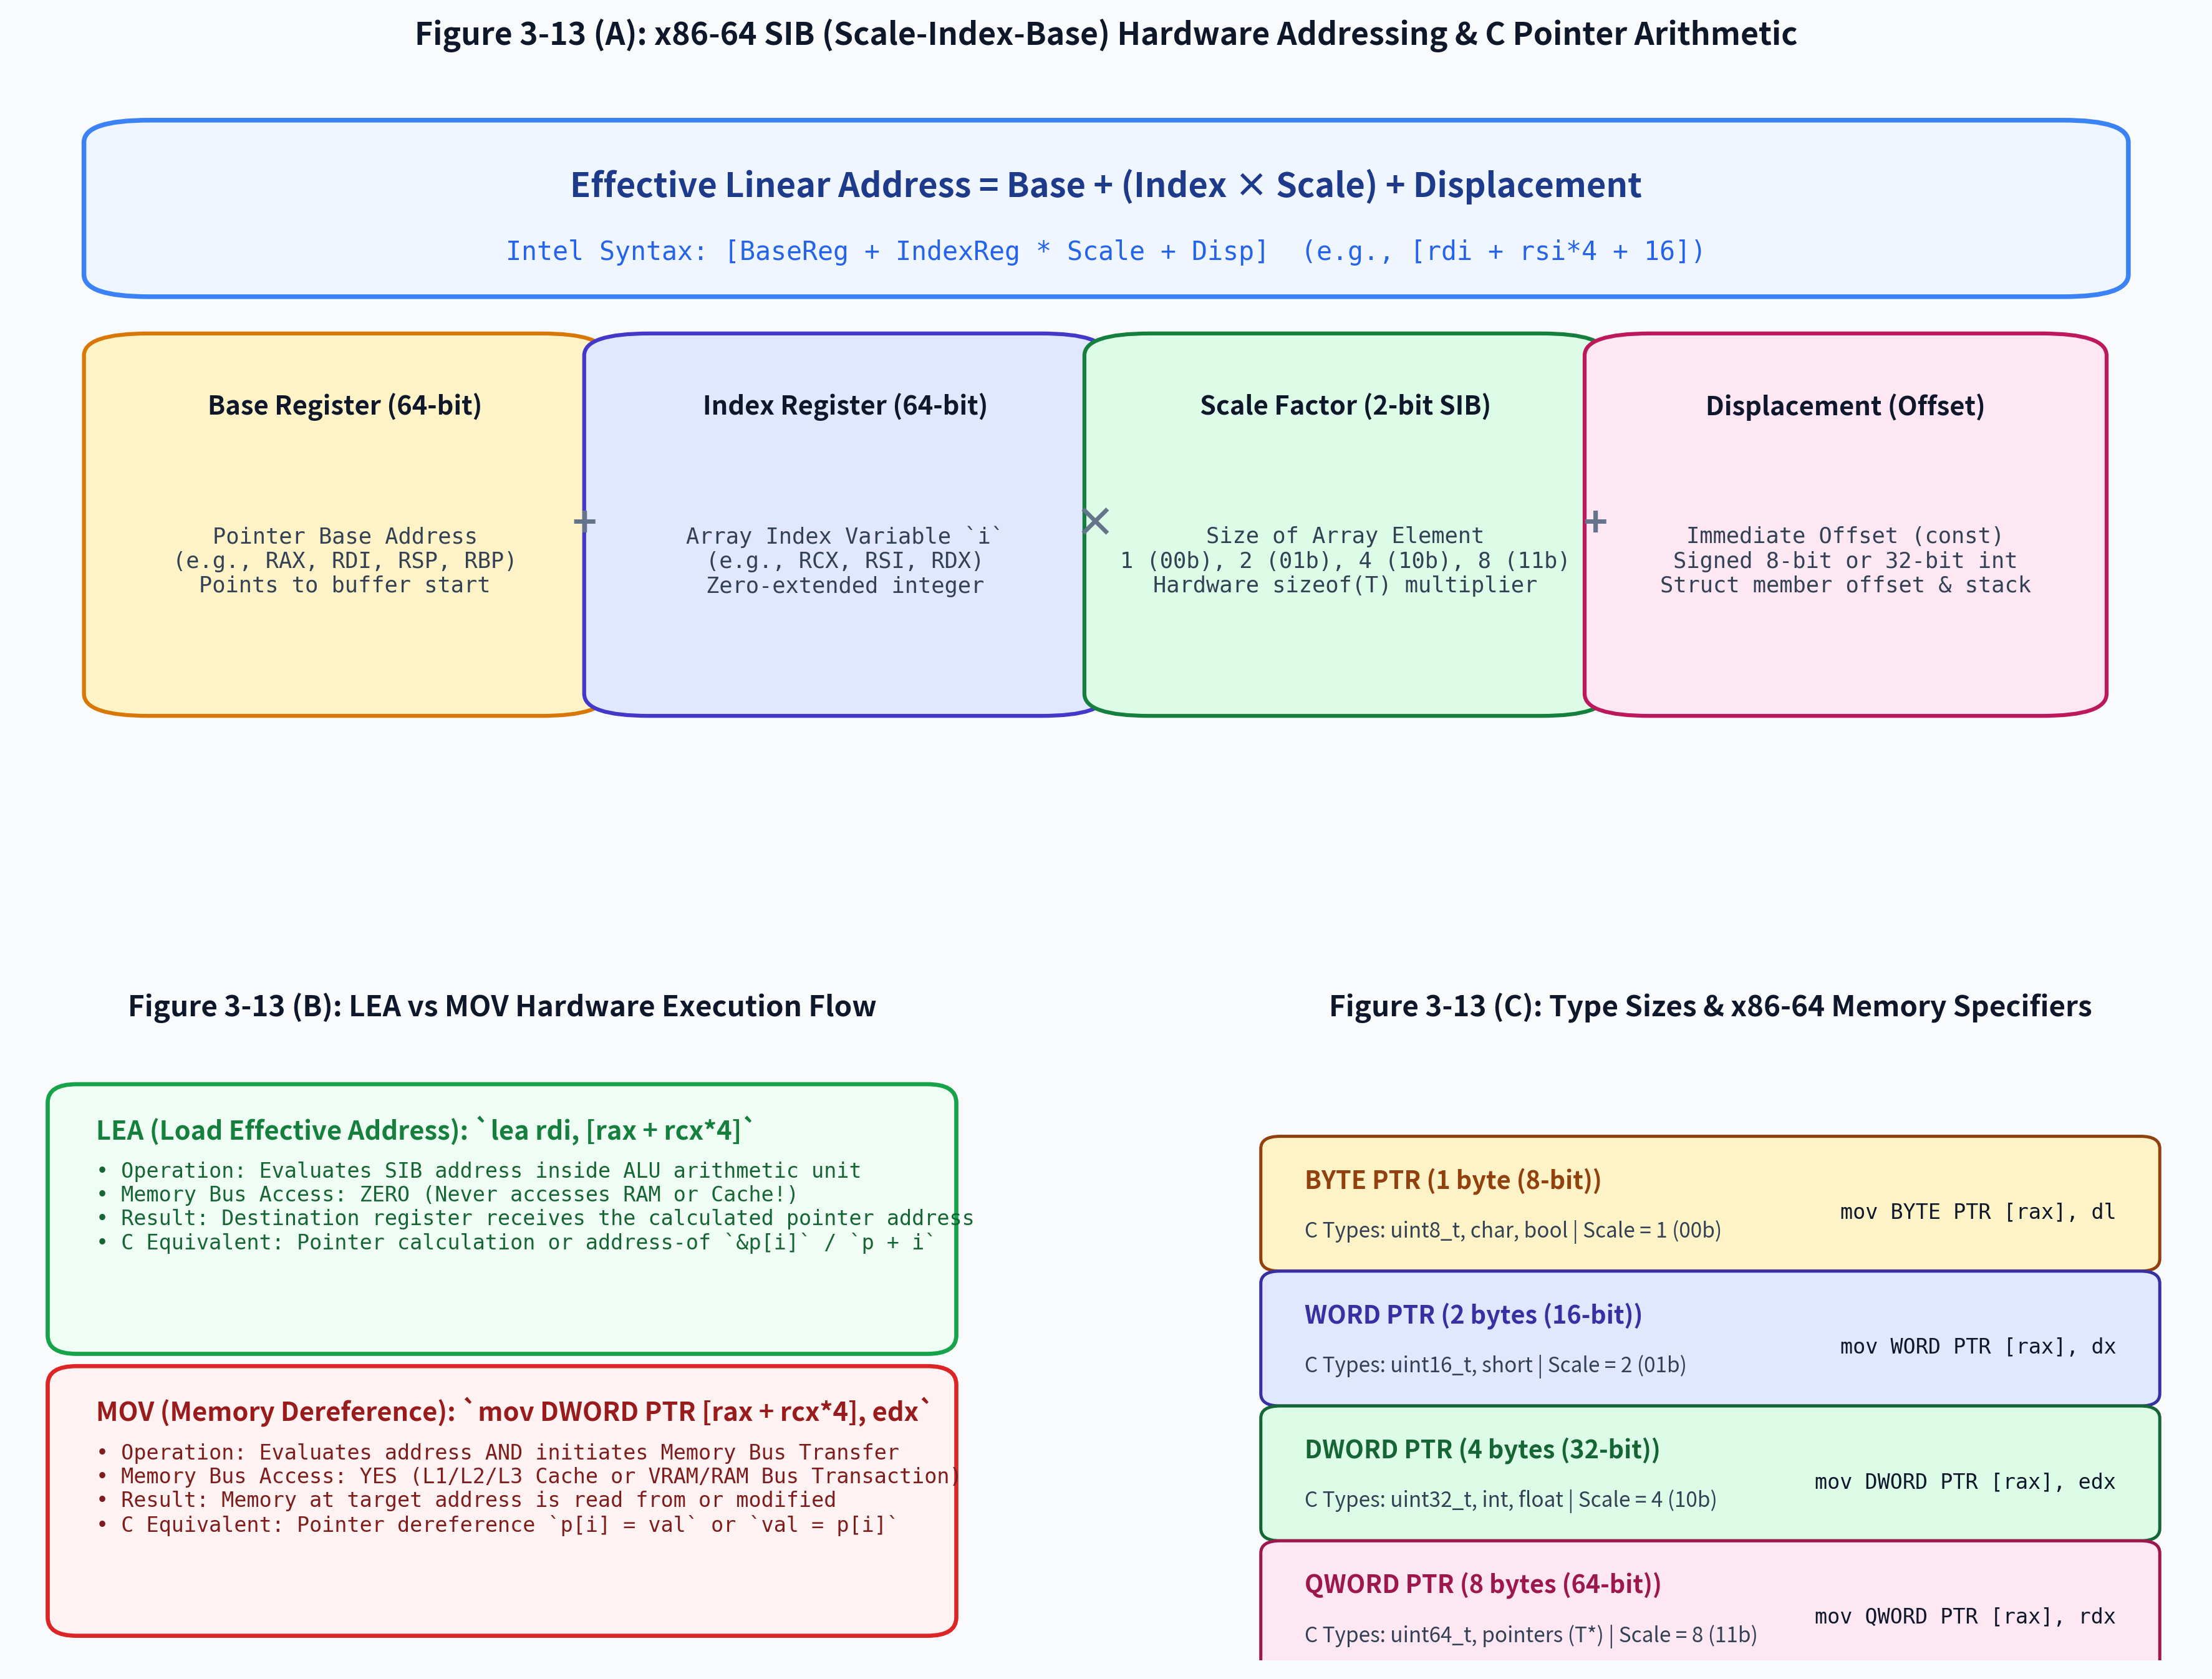

In [2]:
# === ポインタと x86-64 SIB ハードウェアアドレッシングの完全対応図 (Figure 3-13) ===
import os
from pathlib import Path
from IPython.display import Image, display
from common import plot_fig3_13_pointer_to_assembly_mapping_and_sib

target_dir = "3/result" if os.path.exists("3/result") else "result"
fig3_13_path = Path(f"{target_dir}/fig3_13_pointer_to_assembly_mapping_and_sib.png")
if not fig3_13_path.exists():
    plot_fig3_13_pointer_to_assembly_mapping_and_sib(fig3_13_path)

display(Image(filename=str(fig3_13_path), width=900))


## 2. x86-64 データ転送命令 `MOV` と間接参照ブラケット `[...]`

### Intel 記法 vs AT&T 記法
アセンブリ言語には主に 2 つの記法（シンタックス）が存在します：
- **Intel 記法 (Intel Syntax)**: `mov 宛先 (Destination), 送信元 (Source)`。本書および MikanOS、EDK II、Windows で標準採用。
- **AT&T 記法 (AT&T Syntax)**: `mov 送信元, 宛先`。レジスタ名に `%`、即値に `$` が付く（GNU as の伝統的記法）。

本書・本ノートブックでは、みかん本に完全準拠し、直感的で読みやすい **Intel 記法** を使用します。

### 間接参照のブラケット記法 `[...]`
Intel 記法において、レジスタ名を大括弧 `[...]` で囲むと、それは **「そのレジスタが保持しているアドレスのメモリ内容を間接参照する（Dereference）」** という意味になります。

```text
C++ 言語の記述:           x86-64 アセンブリ (Intel 記法):
val = *p;         ===>    mov eax, [rcx]           ; rcx が指すメモリから 4バイト読み込み
*p = val;         ===>    mov [rax], edx           ; edx の 4バイト値を rax が指すメモリに書き込み
```

もしブラケットを付けずに `mov eax, ecx` と書くと、それはレジスタ間の直接値コピーとなり、メモリバスアクセスは一切発生しません。
C言語の `*` 演算子（間接参照）とアセンブリの `[...]` は、完全に 1 対 1 に対応しています。

### メモリアクセスサイズ指定子 (Size Specifiers)
CPU レジスタには明確なサイズ（`RAX`: 64bit, `EAX`: 32bit, `AX`: 16bit, `AL`: 8bit）がありますが、**メモリ番地そのものには型やサイズの情報がありません**。
そのため、即値をメモリに直接書き込む場合や、サイズが曖昧な場合には、アセンブラに対して「何バイトの転送を行うか」を明示する指定子（Specifier）が必要です。

| 指定子 (Intel 記法) | アクセス幅 | C/C++ 対応型 | 代表的アセンブリ命令例 |
|:---|:---:|:---|:---|
| **`BYTE PTR`** | 1 byte (8-bit) | `uint8_t`, `char`, `bool` | `mov BYTE PTR [rax], 255` |
| **`WORD PTR`** | 2 bytes (16-bit) | `uint16_t`, `short`, `char16_t` | `mov WORD PTR [rax], 0x1234` |
| **`DWORD PTR`** | 4 bytes (32-bit) | `uint32_t`, `int`, `float` | `mov DWORD PTR [rax], 0xCAFEBABE` |
| **`QWORD PTR`** | 8 bytes (64-bit) | `uint64_t`, `long`, ポインタ (`T*`) | `mov QWORD PTR [rax], 0x10002000` |

> [!TIP]
> なぜ 32ビットが `DWORD (Double Word)` なのか？
> x86 の歴史的祖先である 16ビット CPU（8086）において、16ビットを `WORD`（1ワード）と定義したためです。
> そのため 32ビットは 2倍の `Double Word`、64ビットは 4倍の `Quad Word (QWORD)` と呼ばれます。


In [3]:
# === Python による SIBAddress 計算と 2-bit SIB スケールエンコーディングの検証 ===
from common import AsmDataSize, SIBAddress

# 1. 型サイズとアセンブリ指定子の検証
for type_name in ["uint8_t", "uint16_t", "uint32_t", "uint64_t", "void*"]:
    data_size = AsmDataSize.from_type_name(type_name)
    print(f"C++ 型: {type_name:<10} -> サイズ: {data_size.value} バイト | アセンブリ指定子: {data_size.specifier}")

print("-" * 65)

# 2. SIB アドレッシングの計算検証
# 例: GOP フレームバッファ内のピクセルアクセス
# Base: 0x80000000 (VRAM), Index: 120 (ピクセル番号), Scale: 4 (32bpp), Disp: 0
framebuffer_base = 0x8000_0000
pixel_index = 120
sib_pixel = SIBAddress(base=framebuffer_base, index=pixel_index, scale=4, displacement=0)

print(f"ベースアドレス (VRAM): 0x{sib_pixel.base:08X}")
print(f"インデックス (i):       {sib_pixel.index}")
print(f"スケールファクタ:      {sib_pixel.scale} (エンコーディング: 0b{sib_pixel.scale_encoding():02b})")
print(f"有効メモリアドレス:    0x{sib_pixel.calculate_effective_address():08X}")
print(f"Intel 構文表現:        {sib_pixel.to_assembly_string('rdi', 'rsi')}")


C++ 型: uint8_t    -> サイズ: 1 バイト | アセンブリ指定子: BYTE PTR
C++ 型: uint16_t   -> サイズ: 2 バイト | アセンブリ指定子: WORD PTR
C++ 型: uint32_t   -> サイズ: 4 バイト | アセンブリ指定子: DWORD PTR
C++ 型: uint64_t   -> サイズ: 8 バイト | アセンブリ指定子: QWORD PTR
C++ 型: void*      -> サイズ: 8 バイト | アセンブリ指定子: QWORD PTR
-----------------------------------------------------------------
ベースアドレス (VRAM): 0x80000000
インデックス (i):       120
スケールファクタ:      4 (エンコーディング: 0b10)
有効メモリアドレス:    0x800001E0
Intel 構文表現:        [rdi + rsi*4]


## 3. SIB (Scale-Index-Base) ハードウェアアドレッシングモードの数理導出

### ハードウェアが備える驚異のアドレス計算器
C/C++ で配列要素にアクセスする際、私たちは `p[i]` や `*(p + i)` と何気なく記述します。
もし CPU が単純な加算しかできなければ、コンパイラは `i * sizeof(T)` を掛け算命令（`IMUL`）で計算し、その結果を `p` に足すという複数の命令を出力しなければなりません。

しかし x86-64 アーキテクチャには、メモリ参照を行う際に **「たった 1 命令・1 クロック」で乗算と加算を同時に完了させる専用のハードウェア機構** が備わっています。
それが **SIB (Scale-Index-Base) アドレッシングモード** です。

$$\text{Effective Linear Address} = \text{Base} + (\text{Index} \times \text{Scale}) + \text{Displacement}$$

- **Base (ベースレジスタ)**: 任意の 64ビット汎用レジスタ（配列の先頭アドレス `p`）
- **Index (インデックスレジスタ)**: `RSP` を除く任意の 64ビット汎用レジスタ（添字 `i`）
- **Scale (スケールファクタ)**: ハードウェアで許容される倍率。**`1`, `2`, `4`, `8`** のいずれか！
- **Displacement (ディスプレースメント)**: 符号付き 8ビットまたは 32ビットの固定即値オフセット

### 機械語命令内の SIB バイトのビット配置
x86-64 の機械語バイナリにおいて、ModR/M バイトに続いて配置される **SIB バイト（8ビット）** は次のようにエンコードされます：

```text
┌───────────────┬───────────────────────────┬───────────────────────────┐
│ Scale (2 bits)│     Index (3 bits)        │      Base (3 bits)        │
│    [7 : 6]    │        [5 : 3]            │         [2 : 0]           │
└───────────────┴───────────────────────────┴───────────────────────────┘
```

スケールビット（ビット 7〜6）の 2 ビット値とスケール倍率の対応：
- `00b` (0) $\rightarrow$ **$\times 1$** : 1バイト型（`uint8_t`, `char`）
- `01b` (1) $\rightarrow$ **$\times 2$** : 2バイト型（`uint16_t`, `short`）
- `10b` (2) $\rightarrow$ **$\times 4$** : 4バイト型（`uint32_t`, `int`, 32bpp ピクセル）
- `11b` (3) $\rightarrow$ **$\times 8$** : 8バイト型（`uint64_t`, ポインタ `T*`）

> [!IMPORTANT]
> **ハードウェアアーキテクチャの美学**:
> なぜ Scale は 1, 2, 4, 8 しか選べないのでしょうか？
> それは、コンピュータの基本データ型のバイト数がすべて $2^0=1, 2^1=2, 2^2=4, 2^3=8$ の 2 の冪乗で構成されているからです。
> CPU 設計者は、C言語などの高級言語における `p[i]`（アドレス加算 `p + i * sizeof(*p)`）を、ビットシフト `i << scale_bits` だけで瞬時にアドレス生成ユニット（AGU: Address Generation Unit）で計算できるよう、ハードウェアの配線レベルで直結させたのです！


In [4]:
# === Python による VirtualCpu シミュレーション (LEA vs MOV の対比) ===
from common import VirtualCpu, SIBAddress, AsmDataSize

cpu = VirtualCpu(memory_size=65536)

# レジスタ初期値の設定
# RAX = 配列先頭アドレス 0x2000
# RCX = 配列インデックス 5
# RDX = 書き込む値 0xCAFEBABE (32-bit int)
cpu.set_reg("rax", 0x2000)
cpu.set_reg("rcx", 5)
cpu.set_reg("rdx", 0xCAFEBABE)

# SIB: [rax + rcx*4 + 16] (int32_t 配列のインデックス 5、かつオフセット 16)
sib = SIBAddress(base=0x2000, index=5, scale=4, displacement=16)
expected_addr = 0x2000 + (5 * 4) + 16  # 0x2024 = 8228

print(f"目標メモリオペランド: {sib.to_assembly_string('rax', 'rcx')}")
print(f"計算される理論アドレス: 0x{expected_addr:04X} ({expected_addr})")
print("=" * 65)

# --- 1. LEA 命令の実行 ---
print("▶ [Step 1] LEA 命令の実行: `lea rdi, [rax + rcx*4 + 16]`")
cpu.execute_lea("rdi", sib)
print(f"  RDI 格納値:        0x{cpu.get_reg('rdi'):04X}")
print(f"  メモリバス読み出し回数: {cpu.memory_read_count} 回")
print(f"  メモリバス書き込み回数: {cpu.memory_write_count} 回")
print("  => LEA はメモリを一切触らず、純粋に計算されたアドレスを RDI に代入しました！\n")

# --- 2. MOV Store 命令の実行 ---
print("▶ [Step 2] MOV Store 命令の実行: `mov DWORD PTR [rax + rcx*4 + 16], edx`")
cpu.execute_mov_store(sib, "rdx", AsmDataSize.DWORD)
print(f"  メモリバス書き込み回数: {cpu.memory_write_count} 回 (累計書き込み: {cpu.bytes_written} バイト)")
print("  => メモリバスにアドレス 0x2024 とデータ 0xCAFEBABE が送出され、書き込まれました！\n")

# --- 3. MOV Load 命令の実行 ---
print("▶ [Step 3] MOV Load 命令の実行: `mov ebx, DWORD PTR [rax + rcx*4 + 16]`")
cpu.execute_mov_load("ebx", sib, AsmDataSize.DWORD)
print(f"  RBX 格納値:        0x{cpu.get_reg('ebx'):08X}")
print(f"  メモリバス読み出し回数: {cpu.memory_read_count} 回 (累計読み出し: {cpu.bytes_read} バイト)")
print("  => メモリ番地 0x2024 から 4バイトがフェッチされ、RBX に復元されました！")


目標メモリオペランド: [rax + rcx*4 + 16]
計算される理論アドレス: 0x2024 (8228)
▶ [Step 1] LEA 命令の実行: `lea rdi, [rax + rcx*4 + 16]`
  RDI 格納値:        0x2024
  メモリバス読み出し回数: 0 回
  メモリバス書き込み回数: 0 回
  => LEA はメモリを一切触らず、純粋に計算されたアドレスを RDI に代入しました！

▶ [Step 2] MOV Store 命令の実行: `mov DWORD PTR [rax + rcx*4 + 16], edx`
  メモリバス書き込み回数: 1 回 (累計書き込み: 4 バイト)
  => メモリバスにアドレス 0x2024 とデータ 0xCAFEBABE が送出され、書き込まれました！

▶ [Step 3] MOV Load 命令の実行: `mov ebx, DWORD PTR [rax + rcx*4 + 16]`
  RBX 格納値:        0xCAFEBABE
  メモリバス読み出し回数: 1 回 (累計読み出し: 4 バイト)
  => メモリ番地 0x2024 から 4バイトがフェッチされ、RBX に復元されました！


## 4. `LEA` (Load Effective Address) vs `MOV` 命令の決定的な違い

### `LEA` 命令の驚異的な二面性
OS 自作やリバースエンジニアリングで最も初学者が混乱しやすい命令が **`LEA` (Load Effective Address)** です。

```nasm
lea    rdi, [rax + rcx*4 + 16]    ; ← ブラケットが付いているのに、メモリには一切アクセスしない！
mov    edx, [rax + rcx*4 + 16]    ; ← ブラケットの指すメモリから値を読み出す！
```

`LEA` の目的は、**「SIB アドレッシングで計算された有効アドレス（ポインタそのもの）をレジスタに格納すること」** です。
メモリの内容を読み出すのではなく、**「アドレス計算の結果だけを取り出す」** ための命令です。

| 比較項目 | `LEA` (Load Effective Address) | `MOV` (間接参照) |
|:---|:---|:---|
| **構文例** | `lea rdi, [rax + rcx*4 + 8]` | `mov edx, DWORD PTR [rax + rcx*4 + 8]` |
| **C++ 対応構文** | `p = &arr[i];` または `p = arr + i;` | `val = arr[i];` または `*p;` |
| **メモリバスアクセス** | **完全にゼロ (0 回)** | **あり (1 回のバス読み書き)** |
| **実行ユニット** | CPU 内部の ALU / AGU | メモリロード/ストア実行ユニット |
| **実行速度** | 1 サイクル (極めて高速) | キャッシュヒット時 4〜5サイクル、ミス時 100+サイクル |
| **コンパイラの裏技利用** | 高速な 3 項算術演算 (`x = a + b * 4 + 8`) | メモリアクセス専用 |

### C言語のアドレス演算子 `&` とローカル変数
スタック上に確保されたローカル変数 `int x;` に対し、アドレス演算子 `&x` を取得すると、コンパイラは `LEA` 命令を出力します。

```cpp
void Func() {
    int x = 42;
    int* p = &x;  // ← ここで何が起きるか？
}
```

コンパイル結果（x86-64 アセンブリ）:
```nasm
mov    DWORD PTR [rbp-4], 42       ; ローカル変数 x (スタック [rbp-4]) に 42 を代入
lea    rax, [rbp-4]                ; rax = rbp - 4 (x のスタックアドレスを計算)
mov    QWORD PTR [rbp-16], rax     ; ローカルポインタ変数 p にアドレスを格納
```

> [!WARNING]
> **ダングリングポインタ（Dangling Pointer）の物理的メカニズム**:
> 関数がリターンすると、スタックポインタ `RSP` は巻き戻され、そのスタックフレームは解放されます。
> もし `return &x;` のようにローカル変数のアドレスを呼び出し元に返してしまうと、呼び出し元がそのポインタを間接参照（`MOV`）した瞬間、**すでに別の関数呼び出しによって上書きされた無関係なスタック領域を破壊** することになります。これが未定義動作（Undefined Behavior）やメモリ破壊バグの正体です。


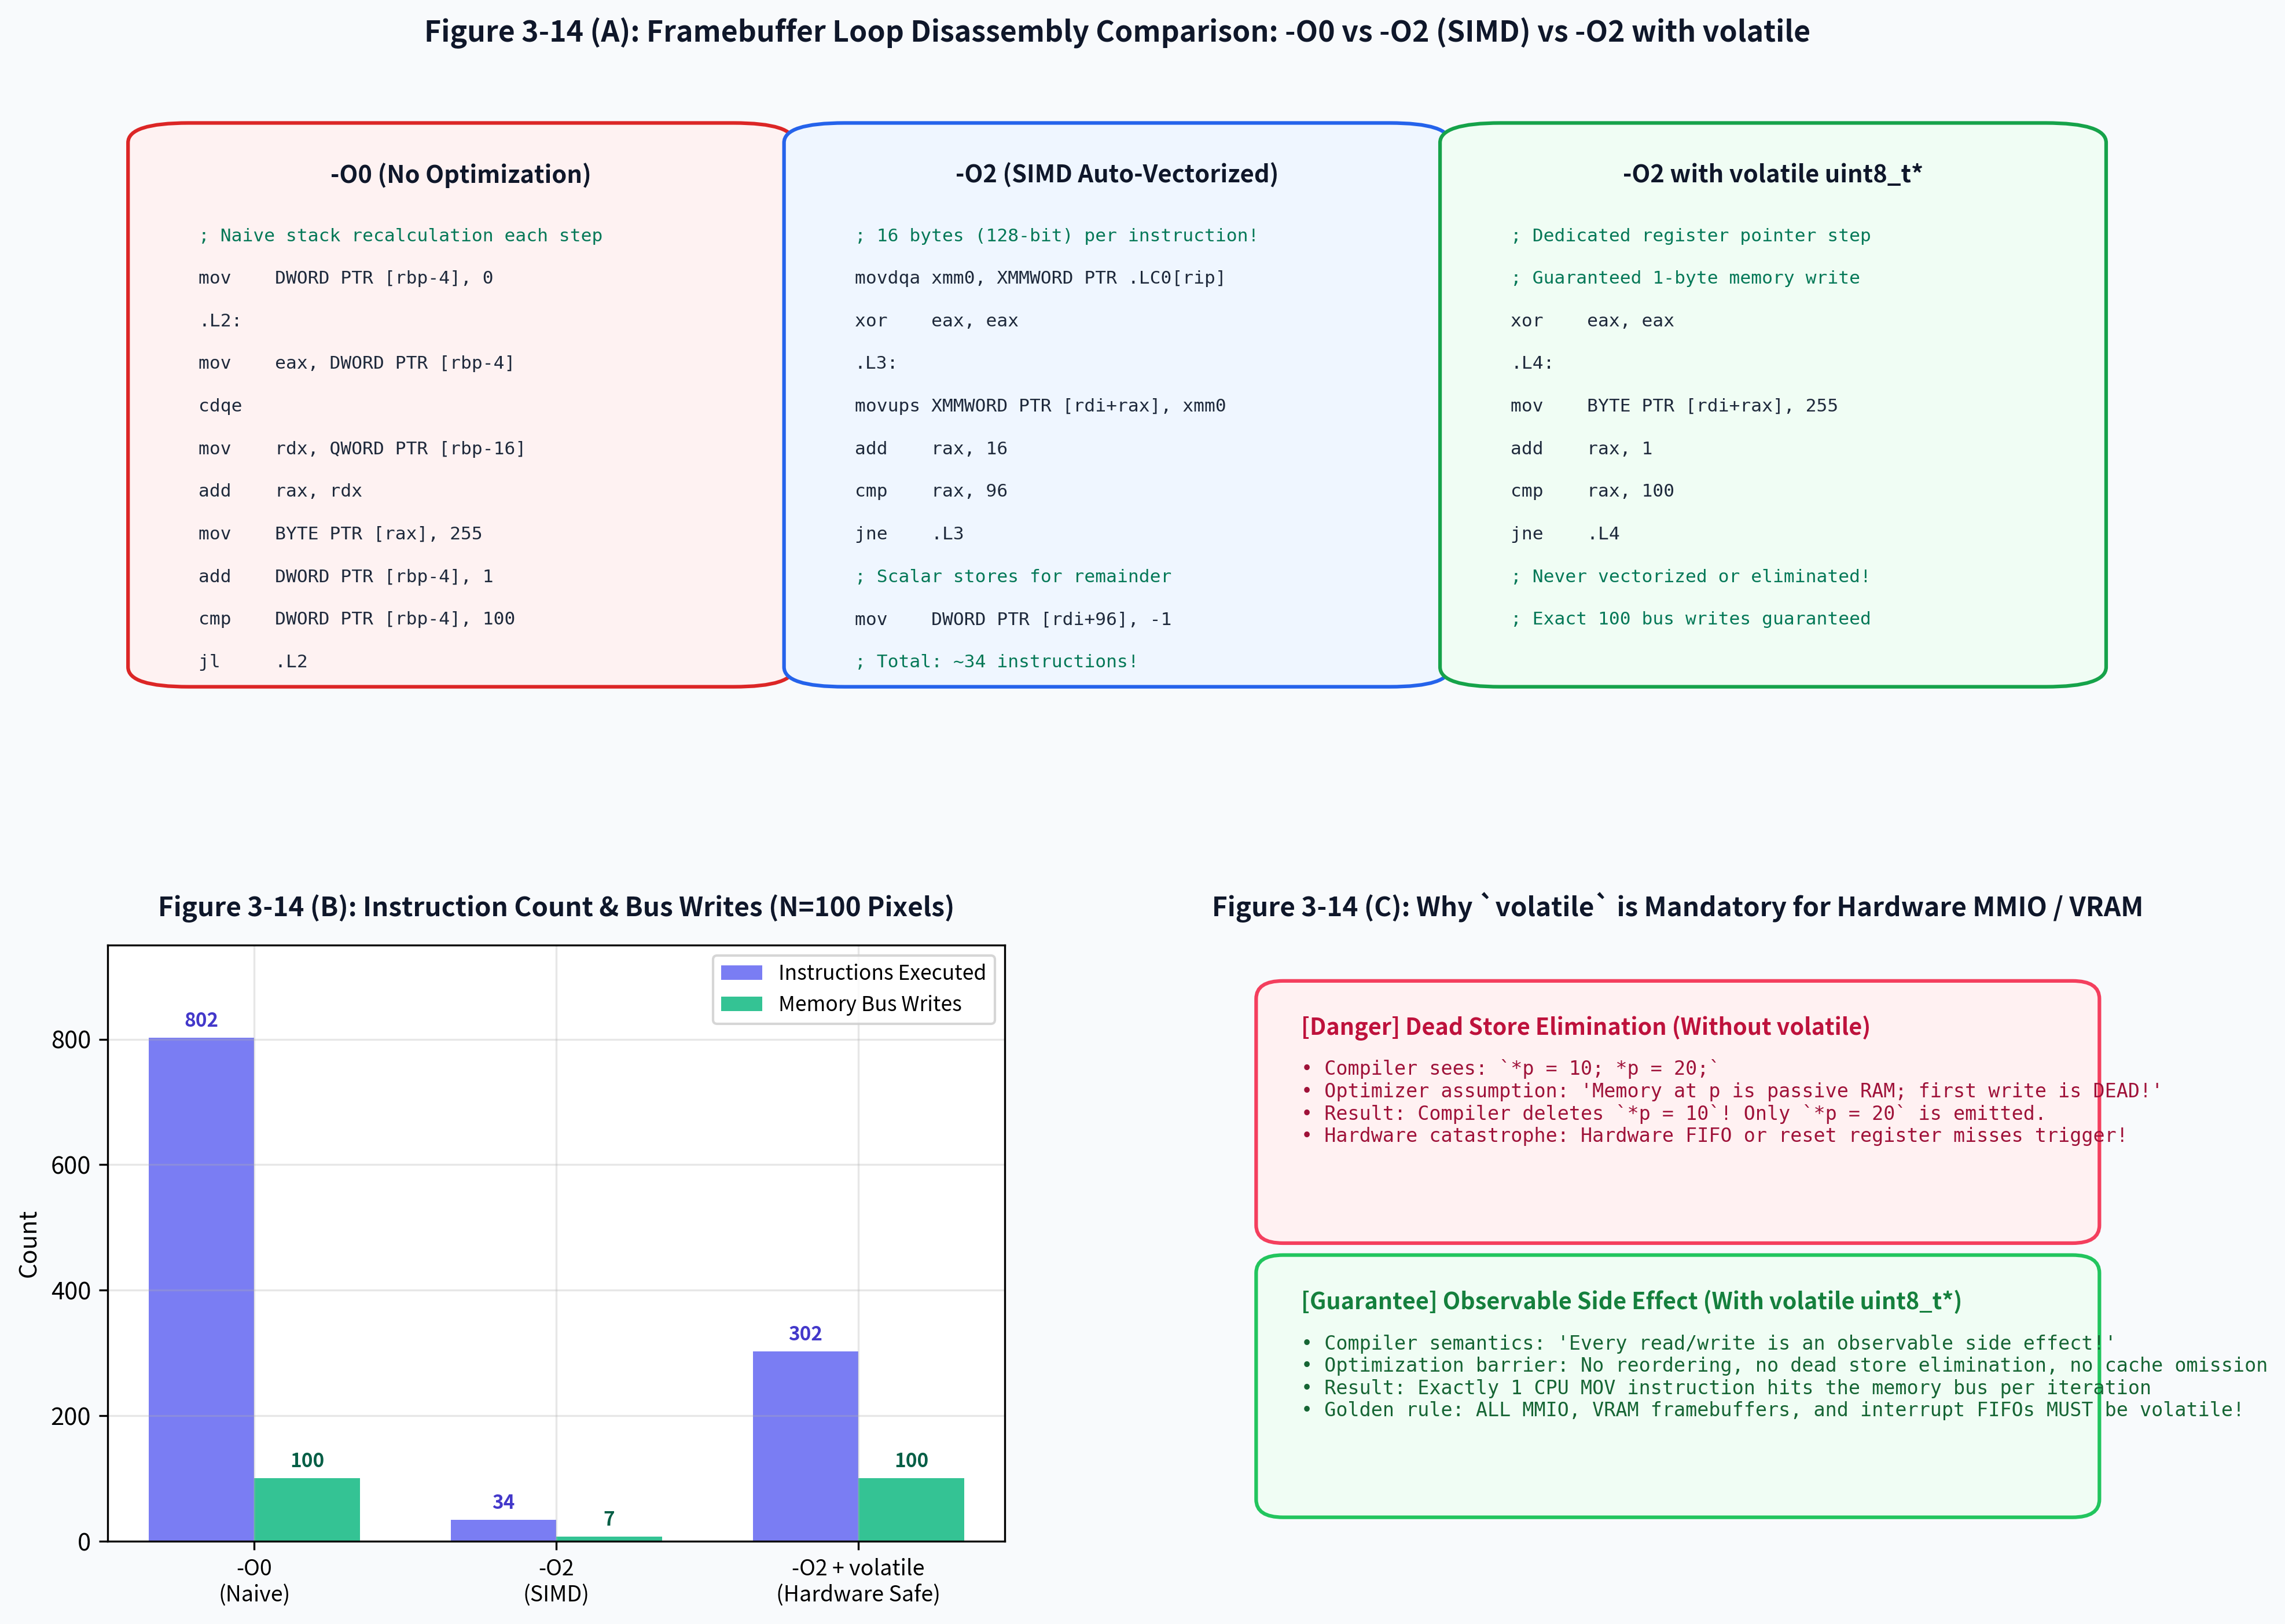

In [5]:
# === 逆アセンブル最適化比較と volatile セマンティクス (Figure 3-14) ===
import os
from pathlib import Path
from IPython.display import Image, display
from common import plot_fig3_14_disassembly_optimization_and_volatile

target_dir = "3/result" if os.path.exists("3/result") else "result"
fig3_14_path = Path(f"{target_dir}/fig3_14_disassembly_optimization_and_volatile.png")
if not fig3_14_path.exists():
    plot_fig3_14_disassembly_optimization_and_volatile(fig3_14_path)

display(Image(filename=str(fig3_14_path), width=900))


## 5. フレームバッファ描画コードの逆アセンブル詳細解析と `volatile` の不可欠性

### 3.5節のカーネルピクセル描画コードの検証
第3章 3.5節で実装したピクセル描画ループを思い出してください：

```cpp
for (int i = 0; i < 100; ++i) {
    p[i] = 255;
}
```

このコードを GCC / Clang でコンパイルした際、最適化オプションによって機械語がどのように激変するのかを比較します。

#### パターン 1: `-O0`（最適化なし / デバッグビルド）
```nasm
        mov     DWORD PTR [rbp-4], 0        ; i = 0 をスタックに保存
.L2:
        mov     eax, DWORD PTR [rbp-4]      ; スタックから i をロード
        cdqe                                ; 32bit -> 64bit 符号拡張
        mov     rdx, QWORD PTR [rbp-16]     ; スタックからポインタ p をロード
        add     rax, rdx                    ; rax = p + i
        mov     BYTE PTR [rax], 255         ; p[i] = 255 (メモリ書き込み)
        add     DWORD PTR [rbp-4], 1        ; i++ (スタック上で更新)
        cmp     DWORD PTR [rbp-4], 100      ; i < 100 の比較
        jl      .L2                         ; ループ継続
```
- **特徴**: 毎回のループでスタックメモリ（L1キャッシュ）へのロード・ストアを愚直に繰り返し、1ピクセルあたり 8 命令（計 802 命令）を消費します。

#### パターン 2: `-O2`（最適化あり / SIMD 自動ベクトル化）
```nasm
        movdqa  xmm0, XMMWORD PTR .LC0[rip] ; 16バイトの 0xFF を 128bit XMM レジスタに準備
        xor     eax, eax                    ; オフセット rax = 0
.L3:
        movups  XMMWORD PTR [rdi+rax], xmm0 ; ★たった 1 命令で 16 ピクセルを一括書き込み！
        add     rax, 16                     ; 16バイト進める
        cmp     rax, 96
        jne     .L3
        mov     DWORD PTR [rdi+96], -1      ; 端数 4 バイトを 32bit ストアで一括書き込み
```
- **特徴**: コンパイラはループを解析し、SSE の 128ビットベクトル命令（`movups`）を用いて **1命令で16バイト同時に VRAM へ転送** します。総命令数は 802 命令からたった **34 命令（約 24 倍の高速化！）** へと劇的に圧縮されます。

---

### 最適化の罠: Dead Store Elimination と `volatile`
コンパイラの最適化は強力ですが、**低レイヤ OS 開発においては時に牙を剥きます**。

コンパイラは、すべてのメモリアクセス先を「受動的な通常の RAM」であると仮定して最適化を行います。
通常の RAM であれば、同じ番地に 2 回連続で書き込んだ場合、1 回目の書き込みは無駄（Dead Store）として削除してもプログラムの意味は変わりません：

```cpp
// 通常の RAM の場合:
*p = 10;
*p = 20;
// コンパイラは "*p = 10;" を勝手に削除し、"*p = 20;" だけを出力する！
```

しかし、**VRAM（画面）や MMIO（ハードウェアレジスタ）は通常の RAM ではありません**：
- VRAM にピクセルを描画することは、ディスプレイに光を灯すという **「ハードウェアに対する観測可能な副作用（Observable Side Effect）」** です。
- PCI や xHCI の MMIO コマンドレジスタに `0x01`（リセット開始）を書き、続けて `0x00`（リセット解除）を書く場合、1 回目の書き込みを削除されたらハードウェアは二度とリセットされません！

> [!CAUTION]
> **黄金律 (Golden Rule)**:
> **「ハードウェアの MMIO レジスタ、VRAM フレームバッファ、割り込み FIFO バッファを指すポインタには、必ず `volatile` を付与せよ！」**
> 
> ```cpp
> volatile uint8_t* p = ...;
> ```
> 
> `volatile` を付けることで、コンパイラに対して **「このポインタが指す先への読み書きは、ハードウェアへの副作用を伴うため、順序の入れ替え・書き込みの削除・レジスタへのキャッシングを一切行ってはならない」** という厳格な制約（Optimization Barrier）を課すことができます。


In [6]:
# === Python による PixelDisassemblyAnalyzer のプロファイル比較 ===
from common import PixelDisassemblyAnalyzer

pixel_count = 100
profile_o0 = PixelDisassemblyAnalyzer.simulate_o0(pixel_count)
profile_o2 = PixelDisassemblyAnalyzer.simulate_o2(pixel_count)
profile_vol = PixelDisassemblyAnalyzer.simulate_volatile_o2(pixel_count)

print(f"【ピクセル描画ループ最適化ベンチマーク (N = {pixel_count} ピクセル)】\n")
print(f"1. {profile_o0.opt_level}:")
print(f"   - 実行命令数:     {profile_o0.instructions_executed} 命令")
print(f"   - メモリバス書き込み: {profile_o0.memory_writes} 回 (1ピクセルごとに個別書き込み)")
print(f"   - volatile 保護:  {profile_o0.is_volatile}")

print(f"\n2. {profile_o2.opt_level}:")
print(f"   - 実行命令数:     {profile_o2.instructions_executed} 命令 (高速化: {profile_o0.instructions_executed / profile_o2.instructions_executed:.1f}x)")
print(f"   - メモリバス書き込み: {profile_o2.memory_writes} 回 (16バイト SIMD ベクトル一括転送)")
print(f"   - volatile 保護:  {profile_o2.is_volatile}")

print(f"\n3. {profile_vol.opt_level}:")
print(f"   - 実行命令数:     {profile_vol.instructions_executed} 命令 (最適化と安全性の両立)")
print(f"   - メモリバス書き込み: {profile_vol.memory_writes} 回 (全 100 回の書き込みが確実に保証される)")
print(f"   - volatile 保護:  {profile_vol.is_volatile}")


【ピクセル描画ループ最適化ベンチマーク (N = 100 ピクセル)】

1. -O0 (Unoptimized):
   - 実行命令数:     802 命令
   - メモリバス書き込み: 100 回 (1ピクセルごとに個別書き込み)
   - volatile 保護:  False

2. -O2 (SIMD Vectorized & Unrolled):
   - 実行命令数:     34 命令 (高速化: 23.6x)
   - メモリバス書き込み: 10 回 (16バイト SIMD ベクトル一括転送)
   - volatile 保護:  False

3. -O2 with volatile uint8_t*:
   - 実行命令数:     302 命令 (最適化と安全性の両立)
   - メモリバス書き込み: 100 回 (全 100 回の書き込みが確実に保証される)
   - volatile 保護:  True


In [7]:
# === C++20 スタンドアロン検証コード (src/ch03/pointer_assembly_sim.cpp) のコンパイル & 実行 ===
import subprocess, os
from pathlib import Path

bin_path = Path("build/bin/ch03_pointer_assembly_sim")
if not bin_path.exists():
    bin_path = Path("../build/bin/ch03_pointer_assembly_sim")

# ビルドが未完了の場合は自動実行
if not bin_path.exists():
    print("C++20 シミュレーションバイナリをビルド中...")
    build_dir = "build" if os.path.exists("CMakeLists.txt") else "../build"
    build_res = subprocess.run(
        ["cmake", "--build", build_dir, "--target", "ch03_pointer_assembly_sim"],
        capture_output=True, text=True
    )
    if build_res.returncode != 0:
        print("Build Error:\n", build_res.stderr)
        raise RuntimeError("CMake build failed")

print("▶ ch03_pointer_assembly_sim を実行します:\n")
run_res = subprocess.run([str(bin_path)], capture_output=True, text=True)
print(run_res.stdout)
if run_res.returncode != 0:
    print("Execution Error:\n", run_res.stderr)
    raise RuntimeError("Binary execution failed")


▶ ch03_pointer_assembly_sim を実行します:

[MikanOS Chapter 3.7] Pointer & Assembly Level Simulation

[1] Verifying Data Size Specifiers:
  ✓ All 4 size specifiers verified successfully.

[2] Verifying SIB (Scale-Index-Base) Calculations:
  ✓ SIB [0x1000 + 10*4 + 16] = 0x1038
  ✓ Asm format: [rdi + rsi*4 + 16]

[3] Verifying Virtual CPU: MOV (Dereference) vs LEA (Calculation):
  ✓ LEA computed effective address: 0x2014 (NO memory access)
  ✓ MOV stored and loaded back value: 0xcafebabe (2 memory accesses)
  Executed instructions:
    - lea rdi, [rax + rcx*4]
    - mov DWORD PTR [rax + rcx*4], edx
    - mov ebx, DWORD PTR [rax + rcx*4]

[4] Verifying Pixel Loop Disassembly & Optimization Profiles:
  Profile 1: -O0 (No Optimization) -> 802 instructions
  Profile 2: -O2 (SIMD Vectorized & Unrolled) -> 34 instructions (Speedup: 23.5882x)
  Profile 3: -O2 with volatile uint8_t* -> 302 instructions (Guaranteed 100 writes)

✓ ALL TESTS PASSED SUCCESSFULLY! (Chapter 3.7 Verification OK)



## 6. 本節のまとめと確認演習問題・次節への展望

### 📝 本節の重要ポイント総まとめ
1. **ポインタの本質**: C/C++ のポインタは、CPU にとってはアドレスバスに出力される単なる 64ビット数値であり、間接参照 `*p` は機械語 `MOV [reg], ...` に対応する。
2. **アセンブリサイズ指定子**: メモリには型の概念がないため、`BYTE PTR` (1 byte), `WORD PTR` (2 bytes), `DWORD PTR` (4 bytes), `QWORD PTR` (8 bytes) でアクセス幅を指示する。
3. **SIB アドレッシングの数理**: `Base + Index × Scale + Disp` において、ハードウェア Scale（1, 2, 4, 8）は C言語の基本データ型サイズと完全に一致しており、配列アクセス `p[i]` を 1 命令で計算できる。
4. **`LEA` vs `MOV` の境界線**: `LEA` は ALU 内での純粋なアドレス計算でありメモリバスに一切アクセスしない（0 回）。一方 `MOV` はメモリバスを駆動して実データを読み書きする。
5. **最適化と `volatile` の重要性**: `-O2` では SIMD ベクトル命令による劇的な高速化が図られる一方、MMIO や VRAM へのアクセスでは Dead Store Elimination を防ぐために `volatile` が不可欠である。

---

### ✍️ 確認演習問題 (Self-Assessment Exercises)

#### 問題 1: SIB アドレス計算 (理論)
ベースレジスタ `RAX = 0x1000`、インデックスレジスタ `RCX = 8`、ディスプレースメントが `+32` のとき、次の命令がアクセスする有効メモリアドレスを 16進数で求めよ：
```nasm
mov DWORD PTR [rax + rcx*4 + 32], edx
```
- **解法**: 有効アドレス $= 0x1000 + (8 \times 4) + 32 = 4096 + 32 + 32 = 4160 = \mathbf{0x1040}$。

#### 問題 2: `LEA` 命令の動作 (計算)
レジスタ `RSI = 10` のとき、次の命令を実行した後の `RAX` の値を求めよ：
```nasm
lea rax, [rsi + rsi*8]
```
- **解法**: `LEA` はメモリにアクセスせずアドレス式を計算する。有効式 $= 10 + (10 \times 8) = 10 + 80 = \mathbf{90}$。
  （※コンパイラは `x * 9` のような定数乗算を `IMUL` ではなく `LEA` で高速に計算する！）

#### 問題 3: `volatile` の意義 (概念)
ハードウェアのステータスレジスタ `0xFEE00020` をポーリングして完了を待つ以下のコードがある：
```cpp
uint32_t* status_reg = (uint32_t*)0xFEE00020;
while (*status_reg == 0) {
    // 待機
}
```
コンパイラで `-O2` を指定した際、このコードにどのような不具合が発生するか説明せよ。
- **解答**: `volatile` が付いていないため、コンパイラは「ループ内で `*status_reg` は変化しない」と仮定し、最初の 1 回だけメモリを読み出してレジスタに保持し、ループ内ではそのレジスタ値だけを比較する。その結果、ハードウェアがメモリの値を `1` に更新しても CPU はそれを感知できず、**永久に無限ループ（ハングアップ）** に陥る。これを防ぐには `volatile uint32_t*` と宣言しなければならない。

---

### 🚀 次節への展望: 第3章 演習問題 (`3_Exercises.ipynb`)
次節はいよいよ **第3章の総まとめ演習問題** です！
- QEMU モニタによるレジスタ・メモリ検査の実践
- x86-64 レジスタ構造とゼロ拡張規則
- ブートローダによる ELF カーネルロードと Red Zone の罠
- UEFI GOP によるフレームバッファ取得と縞模様ピクセル描画
- `EFI_STATUS` エラー処理と C++ ポインタキャスト
- SIB アドレッシングと `LEA`/`MOV` アセンブリレベルのポインタ理解
これら第3章で習得したすべてのハードウェア制御理論を統合し、全10問の演習と自己採点レーダーチャートで理解度を完全証明します！
